# Application Session I — ML Challenge — Tutor Reference

This notebook is a **reference solution and pre-class smoke test** for the student challenge.

It uses only the dataset already referenced by `population_clustering_exercise.ipynb` and downloads it from the AMLG Harvard Dataverse dataset.

## 0. Setup and data download

In [ ]:
import subprocess
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd


def find_repo_root() -> Path:
    """Return the Git repository root, or the current directory if Git is unavailable."""
    try:
        root = subprocess.check_output(
            ["git", "rev-parse", "--show-toplevel"],
            text=True,
            stderr=subprocess.DEVNULL,
        ).strip()
        if root:
            return Path(root)
    except (subprocess.CalledProcessError, FileNotFoundError):
        pass
    return Path.cwd()


ROOT = find_repo_root()
DATA_DIR = ROOT / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = DATA_DIR / "1000_genomes_data.txt"

# from utils import download_file

# if not os.path.exists(path="data"):
#     os.makedirs(name="data")

# download_file(
#     # url="https://dataverse.harvard.edu/api/access/datafile/10494344",
#     url="https://seafile.cloud.uni-hannover.de/d/5d6029c6eaaf410c8b01/files/?p=%2Fpopulation_clustering%2F1000_genomes_data.txt&dl=1",
#     save_filename="data/1000_genomes_data.txt",
# )

if not DATA_PATH.exists():
    print("Downloading the dataset from Seafile...")
    try:
        urllib.request.urlretrieve(
            "https://seafile.cloud.uni-hannover.de/d/5d6029c6eaaf410c8b01/files/?p=%2Fpopulation_clustering%2F1000_genomes_data.txt&dl=1",
            DATA_PATH,
        )
    except Exception as exc:
        raise RuntimeError(
            "Could not download the dataset. Check the internet connection and try again."
        ) from exc

print(f"Using data file: {DATA_PATH}")

Using data file: /workspaces/amlg/data/1000_genomes_data.txt


In [2]:
df = pd.read_csv(DATA_PATH, header=None, sep=r"\s+")

if df.shape[1] <= 3:
    raise ValueError(
        "The downloaded file does not have the expected structure. "
        "Expected 3 metadata columns followed by SNP columns."
    )

identifiers = df.iloc[:, 0].astype(str).to_numpy()
sexes = df.iloc[:, 1].to_numpy()
populations = df.iloc[:, 2].astype(str).to_numpy()
raw_snps = df.iloc[:, 3:].to_numpy()

print(f"Individuals: {len(df):,}")
print(f"SNP positions: {raw_snps.shape[1]:,}")
print(f"Population labels: {sorted(np.unique(populations).tolist())}")
print("\nPopulation counts:")
print(pd.Series(populations).value_counts().sort_index())

Individuals: 995
SNP positions: 10,101
Population labels: ['ACB', 'ASW', 'ESN', 'GWD', 'LWK', 'MSL', 'YRI']

Population counts:
ACB    122
ASW    107
ESN    172
GWD    180
LWK    110
MSL    122
YRI    182
Name: count, dtype: int64


## 1. Quick data check

The original exercise describes 995 individuals, 7 population labels, and 10,101 SNP positions. The code below checks the downloaded file directly.

In [3]:
print(df.iloc[:, :3].head())
print("\nUnique SNP values in a small sample:")
print(np.unique(raw_snps[: min(100, len(raw_snps)), : min(200, raw_snps.shape[1])]))

         0  1    2
0  HG01879  1  ACB
1  HG01880  2  ACB
2  HG01881  2  ACB
3  HG01882  1  ACB
4  HG01883  2  ACB

Unique SNP values in a small sample:
['A' 'C' 'G' 'T']


## 2. Split individuals before creating the representation

We split row indices first. This makes it possible to compute the consensus profile using **training data only**, so the representation does not learn from the held-out test set.

In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and test sets
all_idx = np.arange(len(df))
train_idx, test_idx = train_test_split(
    all_idx,
    test_size=0.25,
    random_state=42,
    stratify=populations,
)

# Extract the training and test sets
train_snps = raw_snps[train_idx]
test_snps = raw_snps[test_idx]
y_train = populations[train_idx]
y_test = populations[test_idx]

print(f"Training individuals: {len(train_idx)}")
print(f"Test individuals: {len(test_idx)}")

Training individuals: 746
Test individuals: 249


## 3. Consensus-aberration representation

This follows the idea from `population_clustering_exercise.ipynb`: each SNP becomes 0 if it matches the consensus base and 1 if it differs.

Here, the consensus is calculated on the **training set only** and then applied unchanged to the test set.

In [ ]:
# Compute the consensus genotype for each column
def consensus_per_column(values: np.ndarray) -> np.ndarray:
    """Return the most frequent value in each column."""
    consensus = []
    for column in values.T:
        unique_values, counts = np.unique(column, return_counts=True)
        consensus.append(unique_values[np.argmax(counts)])
    return np.asarray(consensus)


consensus = consensus_per_column(train_snps)
X_train = (train_snps != consensus).astype(np.float32)
X_test = (test_snps != consensus).astype(np.float32)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Mean aberration rate (train): {X_train.mean():.4f}")

X_train shape: (746, 10101)
X_test shape: (249, 10101)
Mean aberration rate (train): 0.3922


## 4. Baseline 1 — Decision tree

This connects directly to the `DecisionTreeClassifier` introduced in `python_recap_exercise.ipynb`.

In [6]:
from sklearn.tree import DecisionTreeClassifier

model_tree = DecisionTreeClassifier(
    max_depth=12,
    random_state=42,
    class_weight="balanced",
)
model_tree.fit(X_train, y_train)
pred_tree = model_tree.predict(X_test)

## 5. Baseline 2 — Linear SVM

A linear classifier is a useful comparison for a high-dimensional SNP feature space.

In [7]:
from sklearn.svm import LinearSVC

model_linear = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42,
    max_iter=10000,
)
model_linear.fit(X_train, y_train)
pred_linear = model_linear.predict(X_test)

## 6. Evaluation

In [ ]:
from sklearn.metrics import accuracy_score, f1_score


def score_predictions(name: str, y_true: np.ndarray, y_pred: np.ndarray) -> dict:  # noqa: D103
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }


results = pd.DataFrame(
    [
        score_predictions("Decision tree", y_test, pred_tree),
        score_predictions("Linear SVM", y_test, pred_linear),
    ]
).sort_values("macro_f1", ascending=False)

results

,model,accuracy,macro_f1
1,Linear SVM,0.915663,0.911501
0,Decision tree,0.317269,0.306827


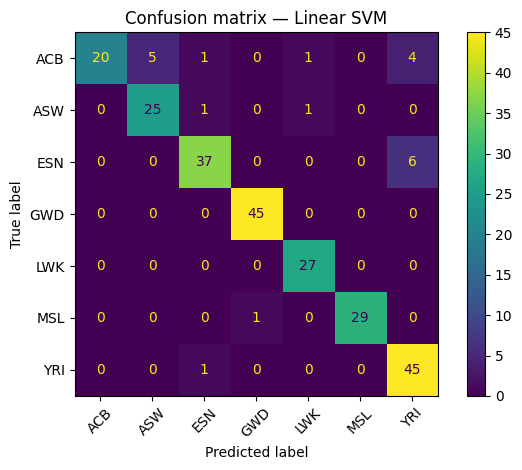

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

best_name = results.iloc[0]["model"]
best_pred = pred_tree if best_name == "Decision tree" else pred_linear

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    labels=sorted(np.unique(populations)),
    xticks_rotation=45,
)
plt.title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.show()

## 7. Optional extension — PCA + linear classifier

Use this as an additional discussion point.   
It connects the challenge to the previous PCA exercise and asks whether dimensionality reduction helps the supervised task.

In [10]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

n_components = min(20, X_train.shape[0] - 1, X_train.shape[1])

model_pca = Pipeline(
    steps=[
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=n_components, random_state=42)),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
    ]
)
model_pca.fit(X_train, y_train)
pred_pca = model_pca.predict(X_test)

score_predictions("PCA + Logistic Regression", y_test, pred_pca)

{'model': 'PCA + Logistic Regression',
 'accuracy': 0.7590361445783133,
 'macro_f1': 0.7529423505990831}

# Discussion Topics

1. Did different representations or models change performance?
2. Was the more complex model always better?
3. Did accuracy and Macro-F1 tell the same story?
4. Which classes were most often confused?
5. Why did we split before computing the training consensus?
6. What can this model **not** tell us about a person beyond these dataset labels?

The goal of the session is **pipeline reasoning**, not a leaderboard.